# 01 — Exploration et validation des données · RadarML Lite, Track B

**But :** comprendre les signaux, **vérifier par la mesure** chaque affirmation faite sur les données,
et en tirer des décisions concrètes de *data processing* et de *feature engineering* pour le Track B.

Chaque section suit le même schéma :

| Étape | Contenu |
| --- | --- |
| **Ce qu'on vérifie** | l'affirmation ou la question |
| **Comment** | la mesure ou la figure utilisée |
| **Résultat** | ✅ confirmé · ❌ infirmé · 🔎 observation |
| **Conséquence** | ce que ça change pour le pipeline |

**Règles respectées :** uniquement des pulses **train** · noms de fichiers utilisés seulement pour les
labels et l'analyse (jamais comme entrée de modèle) · SNR = **requested SNR (dB)**, bruit officiel.
Les figures sont aussi enregistrées dans `reports/figures/eda/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from radarml.constants import CLASSES, SAMPLE_RATE_HZ
from radarml.manifest import load_manifest, select, class_counts
from radarml.noise import degrade_official, to_complex

DATA = ROOT / "data" / "raw" / "recorded_dataset"
FIG_DIR = ROOT / "reports" / "figures" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

refs = load_manifest(DATA, ROOT / "data" / "manifest" / "split_manifest.csv")
train = select(refs, "train")
print(f"{len(refs):,} pulses | train: {len(train):,} | validation: {len(refs) - len(train):,}")

FS = SAMPLE_RATE_HZ
T_US = np.arange(16_800) / FS * 1e6
NOISE_WIN = slice(0, int(20e-6 * FS))                    # fenêtre bruit officielle 0-20 us
SIGNAL_WIN = slice(int(21e-6 * FS), int(119e-6 * FS))    # fenêtre signal officielle 21-119 us

# --- Style : encre sobre, grille discrète, une seule teinte pour une seule série ---
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"      # couleurs catégorielles, ordre fixe
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
DURATION_COLORS = {10: BLUE, 50: ORANGE, 100: AQUA}
POWER_CMAP = LinearSegmentedColormap.from_list("power", ["#fcfcfb", "#9cc3ef", BLUE, "#0d3a73"])
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "lines.linewidth": 2,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight", facecolor="white")

# --- Accès aux pulses ---
_cache = {}
def load_row(ref):
    # Ligne int16 entrelacée (33600,) d'un pulse, lue en memmap (pas de chargement complet).
    if ref.file not in _cache:
        _cache[ref.file] = np.load(DATA / ref.file, mmap_mode="r", allow_pickle=False)
    return np.asarray(_cache[ref.file][0, ref.pulse_index])

def pulse_iq(ref, snr=None):
    # Complexe (16800,) au SNR demandé ; None = enregistrement d'origine sans bruit ajouté.
    row = load_row(ref)
    if snr is not None:
        row = degrade_official(row, ref.source_file, snr, ref.pulse_index)
    return to_complex(row).astype(np.complex128)

def describe(name):
    # Paramètres lus dans le nom de fichier : pour l'ANALYSE uniquement, jamais comme feature.
    parts = name.replace("_recorded.npy", "").split("_")
    return dict(duration_us=int(parts[0].removesuffix("us")),
                bandwidth_mhz=int(parts[2].removesuffix("Mhz")),
                subtype=parts[1].split("#")[0], frequencies=parts[3])

first_pulse = {}                       # un pulse train par configuration
for r in train:
    first_pulse.setdefault(r.file, r)
configs = pd.DataFrame([{"file": f, "label": r.label, **describe(f)} for f, r in first_pulse.items()])
print(f"{len(configs)} configurations")

66,000 pulses | train: 52,800 | validation: 13,200
660 configurations


## 1. Classes et configurations

**Ce qu'on vérifie :** combien d'exemples par classe, et si les classes sont équilibrées.
**Comment :** comptage des pulses train par label, puis croisement avec la durée et la bande.

,configurations,pulses_train,part_%
barker,72,5760,10.9
cw,12,960,1.8
fmcw,96,7680,14.5
fsk,192,15360,29.1
hyp,96,7680,14.5
nlfm,96,7680,14.5
quad,96,7680,14.5


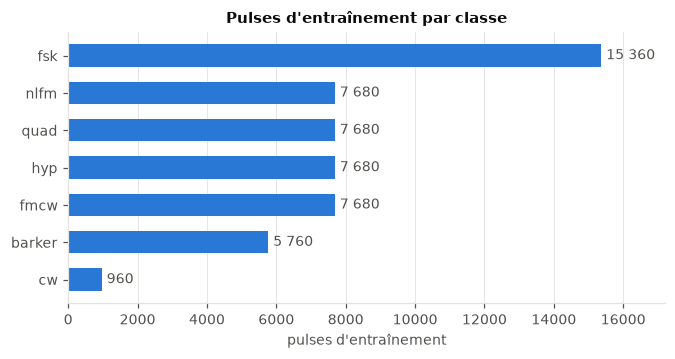

Ratio fsk / cw = 16


In [2]:
summary = pd.DataFrame({"configurations": configs.groupby("label").size(),
                        "pulses_train": pd.Series(class_counts(train))})
summary["part_%"] = (100 * summary.pulses_train / summary.pulses_train.sum()).round(1)
display(summary)

s = summary.pulses_train.sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(s.index, s.values, color=BLUE, height=0.6)
for y, v in enumerate(s.values):
    ax.text(v + 150, y, f"{v:,}".replace(",", " "), va="center", color=INK2)
ax.set(xlabel="pulses d'entraînement", title="Pulses d'entraînement par classe")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, s.max() * 1.12)
save(fig, "01_class_balance"); plt.show()
print(f"Ratio fsk / cw = {s['fsk'] / s['cw']:.0f}")

In [3]:
display(pd.crosstab(configs.label, configs.duration_us).rename_axis(columns="durée (µs)"))
display(pd.crosstab(configs.label, configs.bandwidth_mhz).rename_axis(columns="bande (MHz)"))

durée (µs),10,50,100
label,,,
barker,24,24,24
cw,4,4,4
fmcw,32,32,32
fsk,64,64,64
hyp,32,32,32
nlfm,32,32,32
quad,32,32,32


bande (MHz),0,10,20,40,80
label,,,,,
barker,72,0,0,0,0
cw,12,0,0,0,0
fmcw,0,30,30,30,6
fsk,0,60,60,60,12
hyp,0,30,30,30,6
nlfm,0,30,30,30,6
quad,0,30,30,30,6


**Résultat :** ✅ **déséquilibre confirmé, ratio 16 :** `fsk` = 29 % du train, `cw` = 1,8 %.
🔎 Chaque classe a **autant de pulses de 10, 50 et 100 µs** : la durée ne trahit pas la classe.
🔎 `barker` et `cw` n'ont **pas de bande** (codes de phase / ton pur) ; les chirps et `fsk` vont de 10 à 80 MHz.

**Conséquence :** la métrique (balanced accuracy) donne le même poids à `cw` qu'à `fsk`.
Il faut **pondérer la loss** (poids ∝ 1/effectif) ou **équilibrer les batchs**, et suivre le rappel de `cw`.

## 2. Où se trouve le pulse dans l'enregistrement ?

**Ce qu'on vérifie :** l'affirmation « le pulse est centré dans les 140 µs ».
**Comment :** on calcule l'enveloppe de puissance lissée (0,5 µs), on détecte où elle dépasse le bruit de 6 dB,
sur **un pulse de chacune des 660 configurations**. Ce détecteur n'utilise que le signal.

In [4]:
def detect_pulse(iq, smooth=60, threshold_db=6):
    # Début / fin du pulse (en µs) à partir du signal uniquement.
    env = np.convolve(np.abs(iq) ** 2, np.ones(smooth) / smooth, mode="same")
    noise = env[: int(15e-6 * FS)].mean()
    idx = np.flatnonzero(env > noise * 10 ** (threshold_db / 10))
    return idx[0] / FS * 1e6, idx[-1] / FS * 1e6

rows = []
for f, r in first_pulse.items():
    start, end = detect_pulse(pulse_iq(r))
    rows.append(dict(label=r.label, duration_us=describe(f)["duration_us"], start_us=start, end_us=end))
pos = pd.DataFrame(rows)
pos["measured_us"] = pos.end_us - pos.start_us
pos["centre_us"] = (pos.start_us + pos.end_us) / 2
display(pos.groupby("duration_us")[["start_us", "end_us", "measured_us", "centre_us"]]
           .agg(["min", "max"]).round(2))

start_us         end_us         measured_us        centre_us  \
                 min    max     min     max         min    max       min   
duration_us                                                                
10             65.07  65.07   75.56   75.57       10.49   10.5     70.31   
50             45.07  45.07   95.56   95.57       50.49   50.5     70.31   
100            20.07  20.07  120.56  120.57      100.49  100.5     70.31   

                    
               max  
duration_us         
10           70.32  
50           70.32  
100          70.32

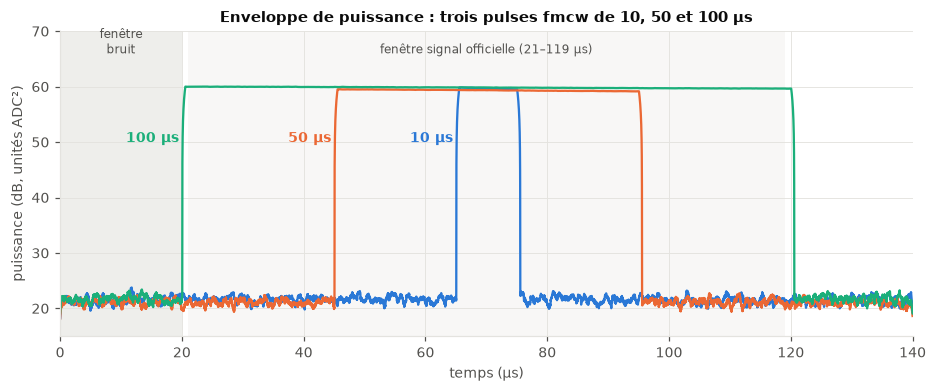

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(0, 20, color=GRID, alpha=0.6, lw=0)
ax.axvspan(21, 119, color=GRID, alpha=0.25, lw=0)
ax.text(10, 66, "fenêtre\nbruit", ha="center", color=INK2, fontsize=8)
ax.text(70, 66, "fenêtre signal officielle (21–119 µs)", ha="center", color=INK2, fontsize=8)
for duration, color in DURATION_COLORS.items():
    ref = next(r for f, r in first_pulse.items() if describe(f)["duration_us"] == duration and r.label == "fmcw")
    env = np.convolve(np.abs(pulse_iq(ref)) ** 2, np.ones(60) / 60, mode="same")
    ax.plot(T_US, 10 * np.log10(env), color=color, lw=1.5)
    start = 70.31 - duration / 2
    ax.text(start - 0.8, 50, f"{duration} µs", color=color, ha="right", fontweight="bold")
ax.set(xlabel="temps (µs)", ylabel="puissance (dB, unités ADC²)", ylim=(15, 70), xlim=(0, 140),
       title="Enveloppe de puissance : trois pulses fmcw de 10, 50 et 100 µs")
save(fig, "02_pulse_position"); plt.show()

**Résultat :** ✅ **centré, et même parfaitement reproductible.** Sur les 660 configurations, le pulse est
centré à **70,3 µs** à ±0,01 µs près, et sa durée mesurée vaut la durée nominale + 0,5 µs.
Début : 65,1 µs (10 µs) · 45,1 µs (50 µs) · 20,1 µs (100 µs) ; fin au plus tard à **120,6 µs**.

**Conséquence (data processing) :** on peut **recadrer avec une règle fixe** (autorisée par le règlement),
par exemple garder **19–122 µs** : tous les pulses sont conservés et on supprime ~27 % d'échantillons
de bruit pur, donc moins de calcul et moins de bruit dans le spectrogramme.

## 3. Le SNR demandé est-il le SNR dans le pulse ?

**Ce qu'on vérifie :** l'affirmation faite au départ, « pour un pulse de 10 µs, le SNR réel dans le pulse est plus
**bas** que le SNR demandé ».

**Comment :** le bruitage officiel mesure la puissance du signal **en moyenne sur 21–119 µs (98 µs)**.
Un pulse de 10 µs n'occupe que ~10 % de cette fenêtre : sa puissance moyenne y est diluée, donc le bruit
ajouté est calculé sur une puissance sous-estimée. On mesure, pour chaque configuration, la puissance
**dans le pulse détecté** et on la compare au bruit total réellement ajouté.

,mean,std,théorie 10·log10(98/durée)
duration_us,,,
10,9.91,0.0,9.91
50,2.92,0.0,2.92
100,0.00,0.0,-0.09


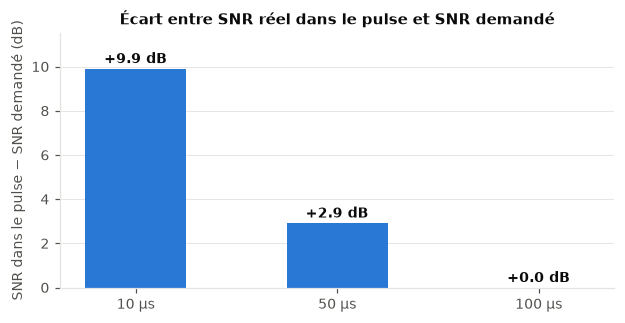

In [6]:
rows = []
for f, r in first_pulse.items():
    iq = pulse_iq(r)
    p = np.abs(iq) ** 2
    start, end = detect_pulse(iq)
    inside = slice(int(start * 1e-6 * FS) + 30, int(end * 1e-6 * FS) - 30)
    noise = p[NOISE_WIN].mean()
    signal_window = p[SIGNAL_WIN].mean() - noise           # ce que mesure le bruitage officiel
    signal_pulse = p[inside].mean() - noise                 # la vraie puissance dans le pulse
    for snr in (0, -10, -20, -30):
        total_noise = max(noise, signal_window / 10 ** (snr / 10))
        rows.append(dict(duration_us=describe(f)["duration_us"], requested_snr=snr,
                         in_pulse_snr=10 * np.log10(signal_pulse / total_noise)))
snr_gap = pd.DataFrame(rows)
snr_gap["gap_db"] = snr_gap.in_pulse_snr - snr_gap.requested_snr
gap = snr_gap.groupby("duration_us").gap_db.agg(["mean", "std"]).round(2)
gap["théorie 10·log10(98/durée)"] = [round(10 * np.log10(98 / d), 2) for d in gap.index]
display(gap)

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar([f"{d} µs" for d in gap.index], gap["mean"], color=BLUE, width=0.5)
for x, v in enumerate(gap["mean"]):
    ax.text(x, v + 0.25, f"+{v:.1f} dB", ha="center", color=INK, fontweight="bold")
ax.set(ylabel="SNR dans le pulse − SNR demandé (dB)", ylim=(0, 11.5),
       title="Écart entre SNR réel dans le pulse et SNR demandé")
ax.grid(axis="x", visible=False)
save(fig, "03_snr_in_pulse"); plt.show()

**Résultat :** ❌ **l'affirmation de départ était fausse, c'est l'inverse.** Le SNR *dans* le pulse est
**plus élevé** que le SNR demandé : **+9,9 dB** pour 10 µs, **+2,9 dB** pour 50 µs, **0 dB** pour 100 µs,
identique à tous les SNR (écart-type 0). C'est exactement la dilution prévue (10·log10(98/durée)).
Un pulse de 10 µs à « −20 dB » est en réalité à environ **−10 dB** dans le pulse.

Mais l'**énergie totale** du pulse rapportée au bruit est la même pour les trois durées : un pulse
court est plus fort mais plus bref. Sur un spectrogramme, il occupe moins de colonnes.

**Conséquence :** à SNR demandé égal, les trois durées ont un niveau de difficulté comparable, pour des raisons
différentes. Il faut **rapporter les scores par durée** en plus de par SNR pour comprendre les erreurs.
(Correction reportée dans `docs/CHALLENGE_BRIEF.md`.)

## 4. SNR d'origine des enregistrements et cibles inatteignables

**Ce qu'on vérifie :** l'affirmation officielle « à +30 dB, environ un tiers des exemples ne reçoivent pas de bruit ».
**Comment :** on mesure le SNR source (même formule que le bruitage officiel) sur 4 pulses par configuration.
Si la cible dépasse le SNR source, le bruitage ne fait rien.

,count,mean,std,min,25%,50%,75%,max
duration_us,,,,,,,,
10,880.0,28.4,0.3,27.3,28.2,28.4,28.6,29.2
50,880.0,35.4,0.3,34.3,35.2,35.4,35.6,36.3
100,880.0,38.3,0.3,37.3,38.1,38.3,38.5,39.3


,SNR demandé,% sans bruit ajouté
0,30,33.3
1,25,0.0
2,20,0.0


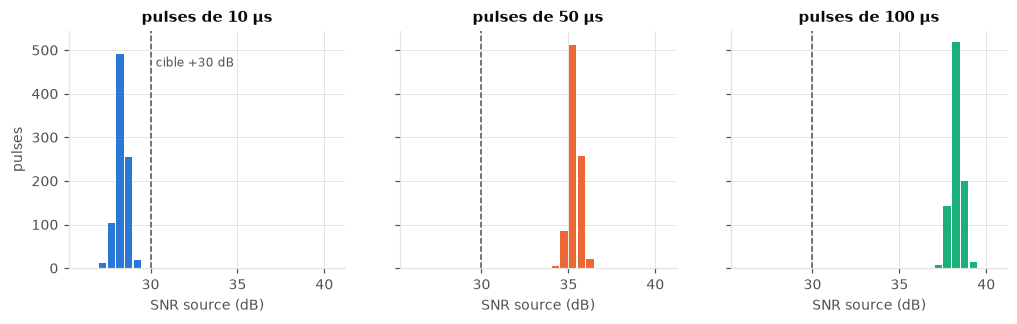

In [7]:
rows = []
for r in train[::20]:
    p = np.abs(pulse_iq(r)) ** 2
    noise = p[NOISE_WIN].mean()
    rows.append(dict(duration_us=describe(r.file)["duration_us"], label=r.label,
                     source_snr_db=10 * np.log10((p[SIGNAL_WIN].mean() - noise) / noise)))
source = pd.DataFrame(rows)
display(source.groupby("duration_us").source_snr_db.describe().round(1))
display(pd.DataFrame({"SNR demandé": [30, 25, 20],
                      "% sans bruit ajouté": [round(100 * (source.source_snr_db < s).mean(), 1) for s in (30, 25, 20)]}))

fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), sharex=True, sharey=True)
bins = np.arange(26, 41, 0.5)
for ax, (duration, color) in zip(axes, DURATION_COLORS.items()):
    ax.hist(source.source_snr_db[source.duration_us == duration], bins=bins, color=color, rwidth=0.85)
    ax.axvline(30, color=INK2, lw=1, ls="--")
    ax.set(title=f"pulses de {duration} µs", xlabel="SNR source (dB)")
axes[0].set_ylabel("pulses")
axes[0].text(30.3, axes[0].get_ylim()[1] * 0.85, "cible +30 dB", color=INK2, fontsize=8)
save(fig, "04_source_snr"); plt.show()

**Résultat :** ✅ **confirmé : 33,3 %** des pulses n'ont aucun bruit ajouté à +30 dB, 0 % à +25 dB.
🔎 Le SNR source dépend de la **durée** : ~28 dB pour les pulses de 10 µs (dilués dans la fenêtre), ~35 dB
pour 50 µs, ~38 dB pour 100 µs. Ce sont donc **tous les pulses de 10 µs** qui restent intacts à +30 dB.

**Conséquence :** +30 dB et +25 dB sont presque identiques pour le modèle. Inutile de sur-représenter
les SNR élevés à l'entraînement ; l'effort doit porter sur les SNR bas.

## 5. Spectrogrammes des 7 classes à 4 SNR

**Ce qu'on vérifie :** à quoi ressemble chaque modulation, quelles classes se ressemblent, quand elles disparaissent.
**Comment :** STFT bilatérale (fenêtre de Hann de 256 échantillons, recouvrement 50 %), puissance en dB
normalisée au maximum de chaque image. Même pulse de 100 µs par classe, bruité à +30, 0, −10, −20 dB.

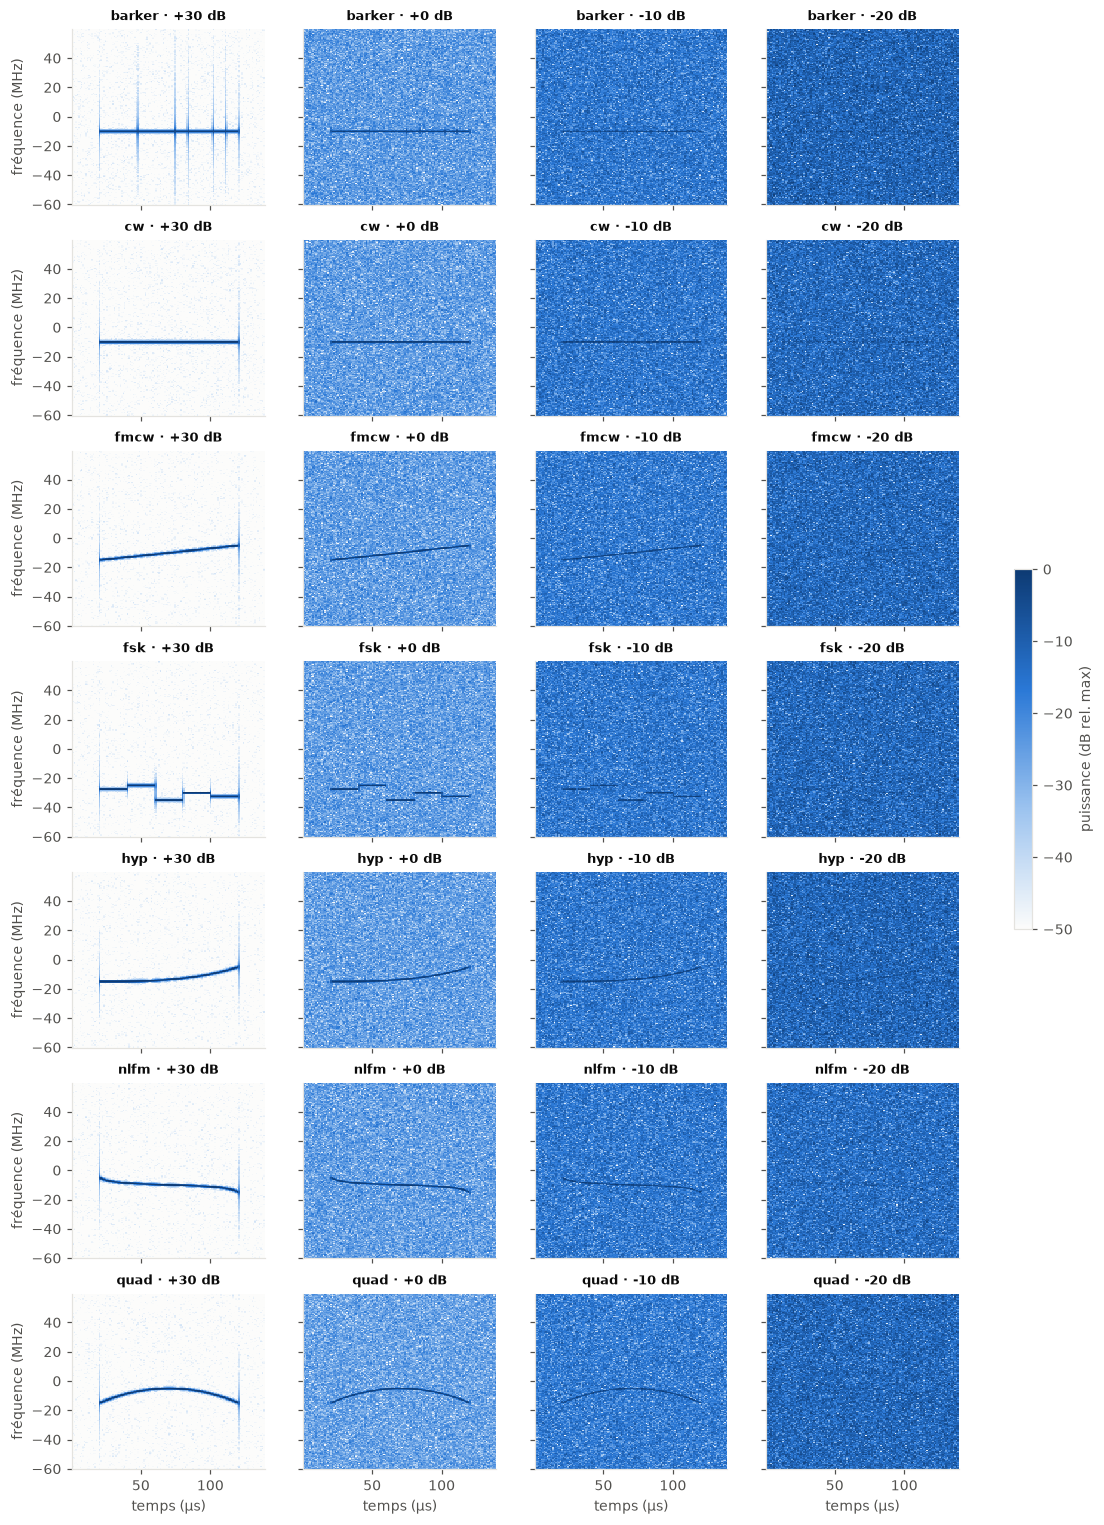

In [8]:
def spectrogram(iq, n_fft=256, hop=128):
    # STFT bilatérale -> fréquences (MHz), temps (µs), puissance (dB rel. au max).
    frames = np.lib.stride_tricks.sliding_window_view(iq, n_fft)[::hop]
    spec = np.fft.fftshift(np.fft.fft(frames * np.hanning(n_fft), axis=1), axes=1)
    power = np.abs(spec) ** 2
    db = 10 * np.log10(power / power.max() + 1e-12)
    t = (np.arange(len(frames)) * hop + n_fft / 2) / FS * 1e6
    f = np.fft.fftshift(np.fft.fftfreq(n_fft, 1 / FS)) / 1e6
    return f, t, db.T

def show_spec(ax, iq, title, n_fft=256, hop=128, vmin=-50):
    f, t, db = spectrogram(iq, n_fft, hop)
    mesh = ax.pcolormesh(t, f, db, shading="auto", vmin=vmin, vmax=0, cmap=POWER_CMAP, rasterized=True)
    ax.set_title(title, fontsize=8.5); ax.grid(False)
    return mesh

def first_of(label, duration):
    return next(r for f, r in first_pulse.items() if r.label == label and describe(f)["duration_us"] == duration)

examples = {c: first_of(c, 100) for c in CLASSES}
snrs = [30, 0, -10, -20]
fig, axes = plt.subplots(len(CLASSES), len(snrs), figsize=(13, 17), sharex=True, sharey=True)
for i, (cls, ref) in enumerate(examples.items()):
    for j, snr in enumerate(snrs):
        mesh = show_spec(axes[i, j], pulse_iq(ref, snr), f"{cls} · {snr:+d} dB")
for ax in axes[-1]: ax.set_xlabel("temps (µs)")
for ax in axes[:, 0]: ax.set_ylabel("fréquence (MHz)")
fig.colorbar(mesh, ax=axes, shrink=0.25, label="puissance (dB rel. max)")
save(fig, "05_spectrograms_by_class_snr"); plt.show()

**Résultat :** ✅ à fort SNR, **chaque classe a une signature visuelle distincte** :

| Classe | Forme sur le spectrogramme |
| --- | --- |
| `cw` | ligne horizontale (fréquence constante) |
| `barker` | ligne horizontale **+ traits verticaux** aux sauts de phase de 180° |
| `fmcw` | droite oblique (fréquence qui varie linéairement) |
| `fsk` | paliers (4 fréquences successives) |
| `hyp` | courbe plate puis de plus en plus raide |
| `nlfm` | courbe en S |
| `quad` | arc de parabole (∩ ou ∪) |

⚠️ **Confusion n°1 attendue : `barker` ↔ `cw`.** Dès 0 dB, les traits verticaux du Barker disparaissent dans le bruit
et il ne reste qu'une ligne horizontale, comme `cw`. C'est d'autant plus grave que `cw` est la classe minoritaire.

⚠️ **Confusion n°2 attendue : les 4 chirps entre eux** (`fmcw`, `hyp`, `nlfm`, `quad`). Ils ne diffèrent que par la
**courbure** de la trace ; à −10 dB la trace s'amincit et la courbure devient difficile à lire.

🔎 À −20 dB, plus rien n'est visible à l'œil sur un pulse de 100 µs. Le modèle devra accumuler l'information faible
répartie sur toute la trace.

**Conséquence :** la représentation doit garder les **détails fins** (transitoires des sauts de phase, courbure).
Dans les matrices de confusion, surveiller en priorité `barker`/`cw` et les chirps.

## 6. Variabilité à l'intérieur d'une classe

**Ce qu'on vérifie :** si une classe a toujours la même apparence.
**Comment :** 4 configurations tirées au hasard par classe (durées, bandes, fréquences différentes), sans bruit ajouté.

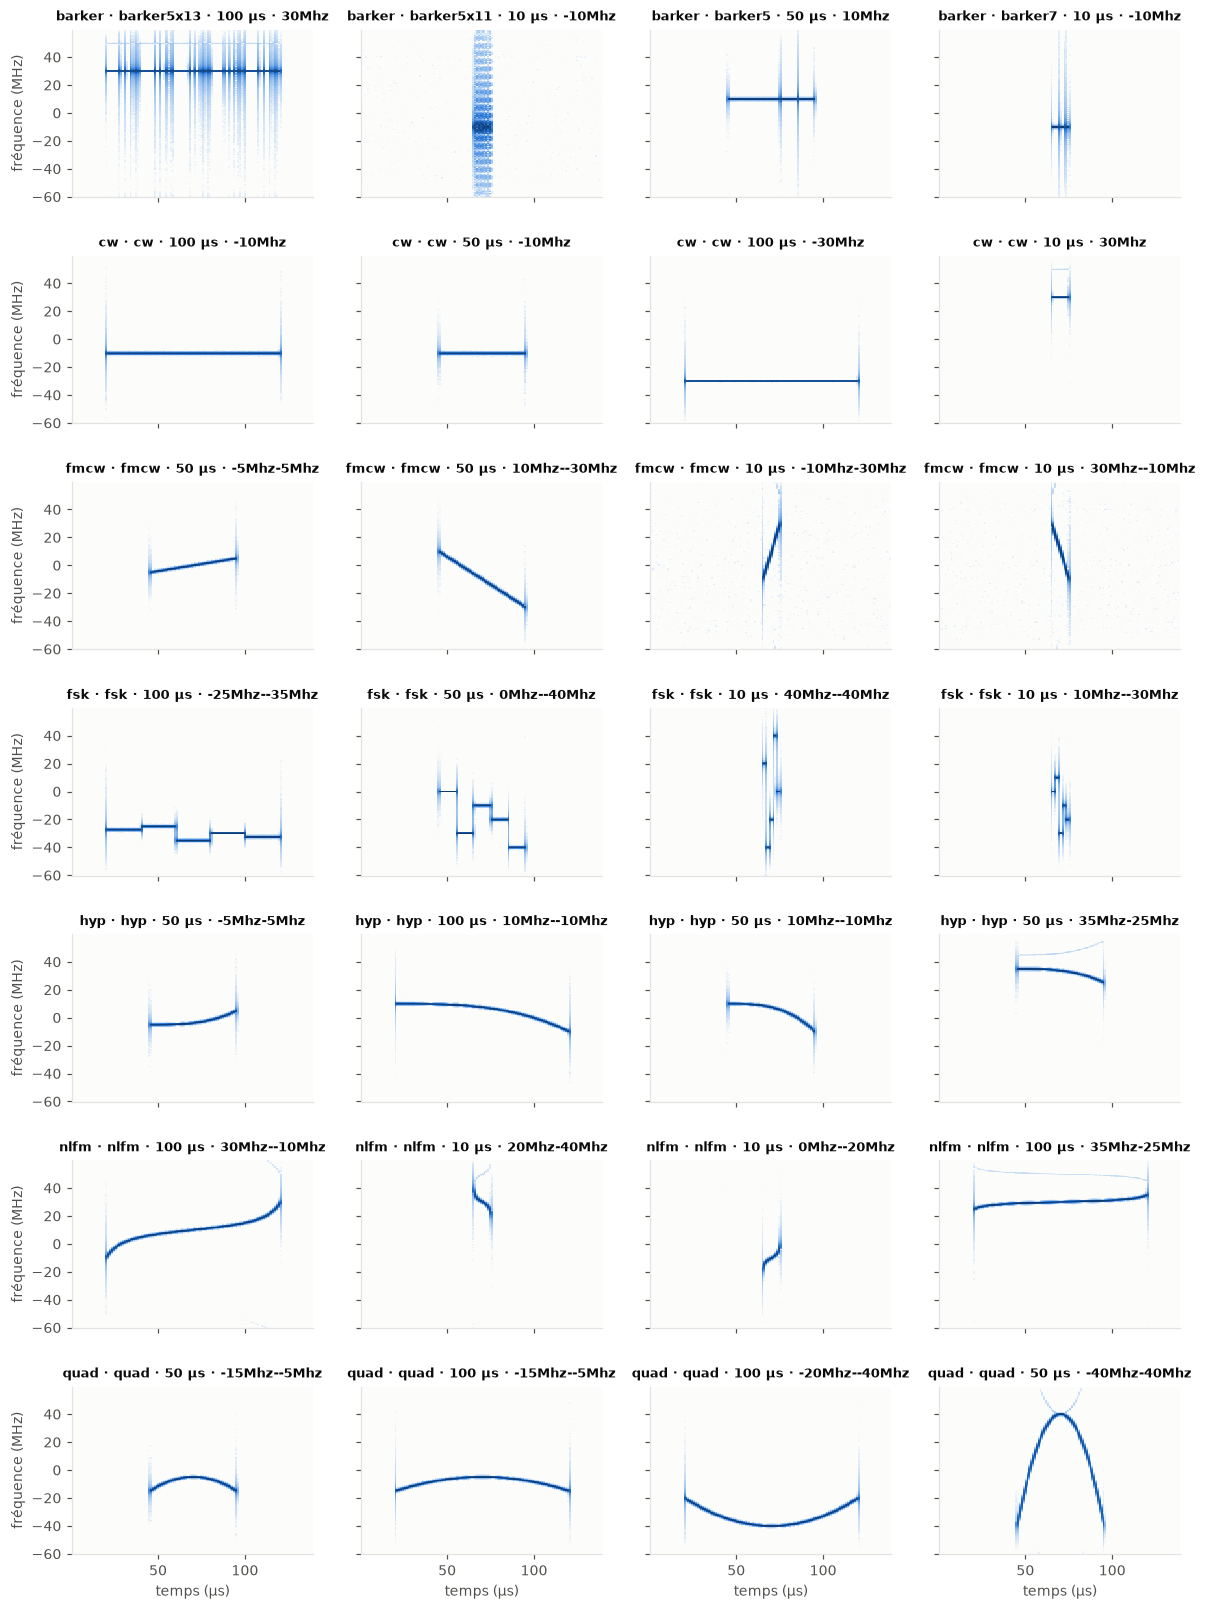

In [9]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(13, 18), sharex=True, sharey=True,
                         gridspec_kw={"hspace": 0.35})
for i, cls in enumerate(CLASSES):
    names = sorted(configs.file[configs.label == cls])
    for j, name in enumerate(rng.choice(names, size=4, replace=False)):
        d = describe(name)
        show_spec(axes[i, j], pulse_iq(first_pulse[name]),
                  f"{cls} · {d['subtype']} · {d['duration_us']} µs · {d['frequencies']}")
for ax in axes[:, 0]: ax.set_ylabel("fréquence (MHz)")
for ax in axes[-1]: ax.set_xlabel("temps (µs)")
save(fig, "06_intra_class_variability"); plt.show()

**Résultat :** ✅ **variabilité très forte à l'intérieur de chaque classe :** sens montant ou descendant,
fréquence centrale de −40 à +40 MHz, bande de 10 à 80 MHz, durée de 10 à 100 µs (×10 en largeur sur l'image).

🔎 `barker` change complètement d'aspect : un code court sur un pulse long donne une ligne + quelques traits, mais un
**code composé (5×11, 5×13) sur 10 µs** a des « chips » de 0,15–0,18 µs et son énergie **s'étale sur toute la bande**
(un bloc vertical). Le modèle doit apprendre les deux aspects pour la même classe.

🔎 `quad` existe en ∩ et en ∪ ; `hyp` monte ou descend mais reste toujours « plate puis raide ».

🔎 **Artefact matériel découvert :** pour les signaux vers +30/+35 MHz, une **trace fantôme faible** apparaît, symétrique
par rapport à +40 MHz (30 → 50 MHz). On la voit sur `barker`, `cw`, `hyp` et `nlfm` : elle vient du récepteur, pas de
la classe. Ce n'est pas un raccourci, mais le modèle devra apprendre à l'ignorer.

**Conséquence (feature engineering) :** le modèle doit être **insensible à la position en fréquence, au sens et à la
durée** → architecture convolutive avec *pooling* global. Augmentations à **tester sur la validation** (elles
conservent la classe en théorie) : miroir fréquentiel (conjugué complexe : montant ↔ descendant) et léger décalage
de fréquence. À éviter : l'inversion temporelle, qui transformerait un `hyp` « plat puis raide » en « raide puis plat ».

## 7. Quelle fenêtre STFT ? (compromis temps / fréquence)

**Ce qu'on vérifie :** l'idée qu'une fenêtre courte montre les changements rapides et une longue sépare les fréquences.
**Comment :** (a) on calcule les **échelles de temps** des modulations (durée d'un palier FSK, d'un « chip » Barker)
et on les compare à la durée des fenêtres ; (b) on affiche `fsk`, `barker` et `nlfm` avec 3 fenêtres.

In [10]:
windows = {n: n / FS * 1e6 for n in (64, 256, 1024)}
display(pd.DataFrame({"n_fft": list(windows), "durée fenêtre (µs)": [round(v, 2) for v in windows.values()],
                      "résolution fréquence (kHz)": [round(FS / n / 1e3, 1) for n in windows],
                      "trames (hop = n_fft/2)": [1 + (16_800 - n) // (n // 2) for n in windows]}))

code_lengths = {"fsk (4 paliers)": 4, "barker5": 5, "barker7": 7, "barker11": 11, "barker13": 13,
                "barker5x11": 55, "barker5x13": 65}
scales = pd.DataFrame({f"{d} µs": {k: round(d / n, 2) for k, n in code_lengths.items()} for d in (10, 50, 100)})
scales.index.name = "durée d'un palier / chip (µs)"
display(scales)

,n_fft,durée fenêtre (µs),résolution fréquence (kHz),trames (hop = n_fft/2)
0,64,0.53,1875.0,524
1,256,2.13,468.8,130
2,1024,8.53,117.2,31


,10 µs,50 µs,100 µs
durée d'un palier / chip (µs),,,
fsk (4 paliers),2.50,12.50,25.00
barker5,2.00,10.00,20.00
barker7,1.43,7.14,14.29
barker11,0.91,4.55,9.09
barker13,0.77,3.85,7.69
barker5x11,0.18,0.91,1.82
barker5x13,0.15,0.77,1.54


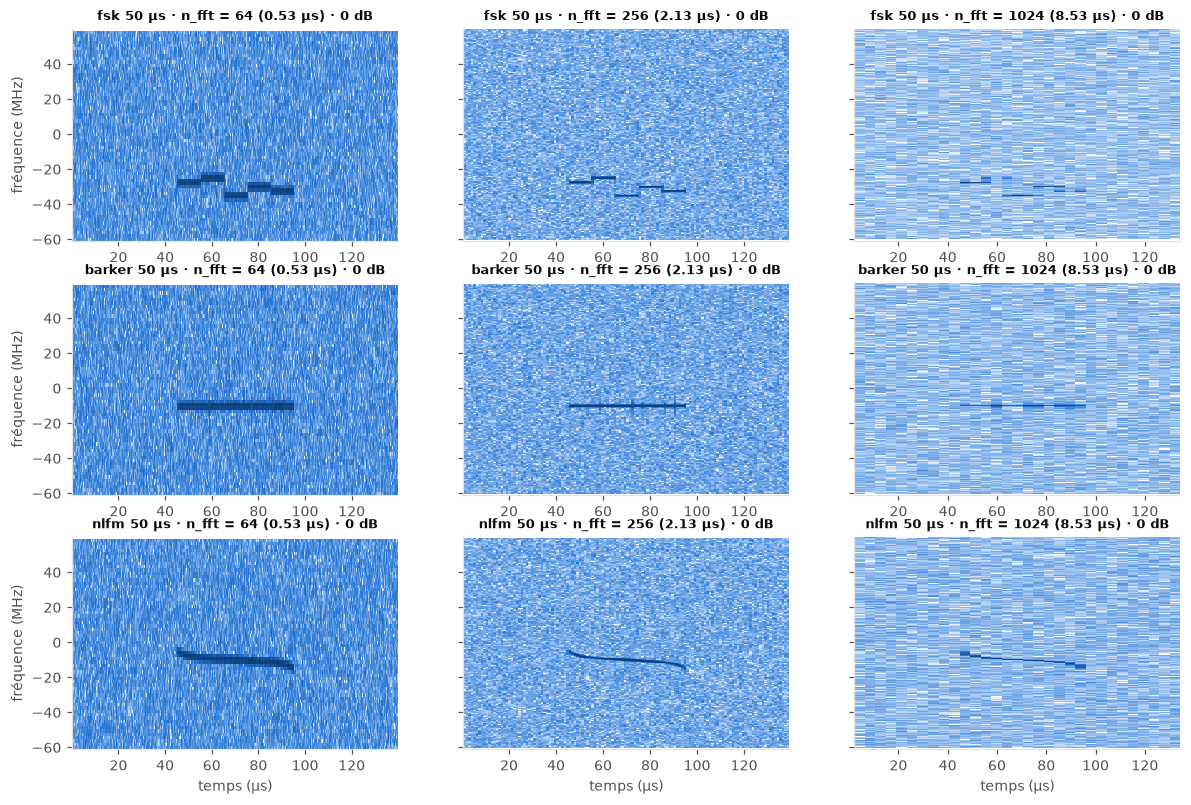

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(13, 8.5), sharey=True)
for i, cls in enumerate(["fsk", "barker", "nlfm"]):
    iq = pulse_iq(first_of(cls, 50), 0)
    for j, n_fft in enumerate(windows):
        show_spec(axes[i, j], iq, f"{cls} 50 µs · n_fft = {n_fft} ({windows[n_fft]:.2f} µs) · 0 dB", n_fft, n_fft // 2)
for ax in axes[:, 0]: ax.set_ylabel("fréquence (MHz)")
for ax in axes[-1]: ax.set_xlabel("temps (µs)")
save(fig, "07_stft_window"); plt.show()

**Résultat :** ✅ **compromis confirmé**, visible sur la figure :

- **64 (0,53 µs)** : paliers FSK nets dans le temps, mais traces épaisses (résolution 1,9 MHz) et bruit strié.
- **256 (2,1 µs)** : le meilleur compromis à l'œil. Traces fines, courbure et paliers lisibles, sauts de phase Barker
  visibles en petits traits.
- **1024 (8,5 µs)** : très fin en fréquence, mais paliers FSK et sauts Barker brouillés, et 31 trames seulement.

🔎 Le tableau montre que les chips des codes Barker composés (0,15–1,8 µs) sont **plus courts que la fenêtre de 256**.
Ces sauts de phase ne se voient donc pas un par un : ils apparaissent comme un **étalement en fréquence**.
Les paliers FSK d'un pulse de 10 µs (2,5 µs) sont à peine plus longs que la fenêtre de 256.

**Conséquence (feature engineering) :** point de départ **n_fft = 256, hop = 128**. Expérience prioritaire :
**empiler plusieurs résolutions en canaux** (64 + 256, voire 1024) pour donner au modèle à la fois le détail temporel
et le détail fréquentiel.

## 8. Pulse court vs pulse long face au bruit

**Ce qu'on vérifie :** la conséquence de la section 3 sur l'image vue par le modèle.
**Comment :** même classe (`quad`), pulse de 10 µs et de 100 µs, aux mêmes SNR demandés.

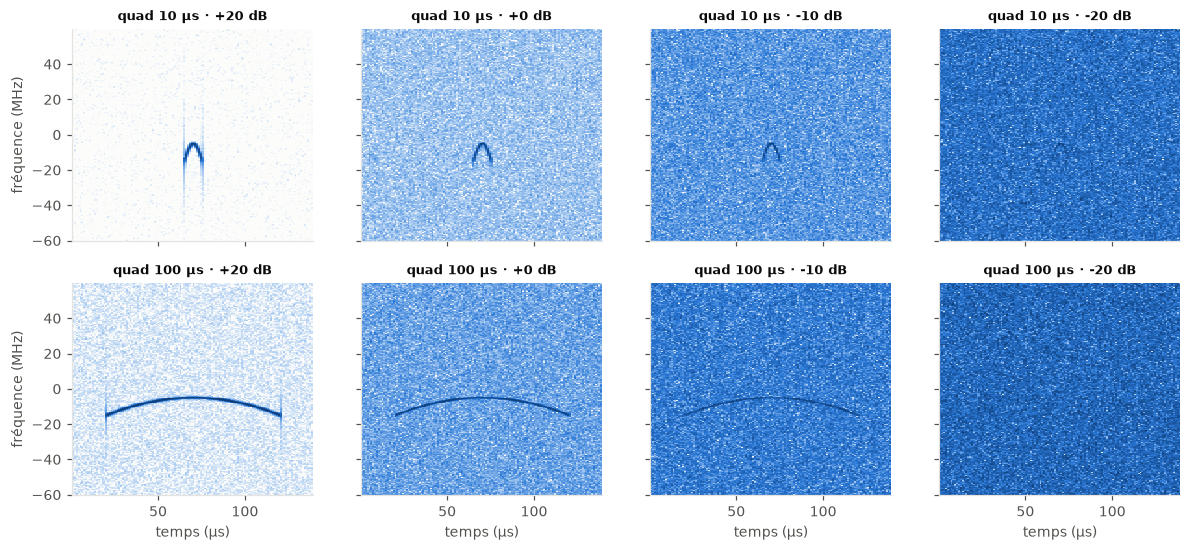

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True, sharey=True)
for i, duration in enumerate((10, 100)):
    ref = first_of("quad", duration)
    for j, snr in enumerate([20, 0, -10, -20]):
        show_spec(axes[i, j], pulse_iq(ref, snr), f"quad {duration} µs · {snr:+d} dB")
for ax in axes[:, 0]: ax.set_ylabel("fréquence (MHz)")
for ax in axes[-1]: ax.set_xlabel("temps (µs)")
save(fig, "08_short_vs_long"); plt.show()

**Résultat :** ✅ **confirme la section 3 sur l'image.** À −10 dB, l'arc du pulse de 10 µs est plus contrasté que celui
de 100 µs ; à −20 dB, l'arc du 10 µs se devine encore, celui du 100 µs a disparu. Mais le pulse court n'occupe
que ~5 colonnes du spectrogramme sur 130.

**Conséquence :** le même motif peut faire 5 ou 50 colonnes de large. Il faut une architecture qui gère des
**tailles de motif très différentes** (pooling global, champ réceptif suffisant). Ne pas redimensionner l'image d'une
façon qui écraserait les pulses courts.

## 9. Recherche de raccourcis d'acquisition

**Ce qu'on vérifie :** que la classe ne se devine pas par un artefact de mesure (niveau de bruit, puissance,
décalage DC). Les organisateurs demandent explicitement si le modèle exploite la forme d'onde ou ce genre d'artefact.
**Comment :** 4 pulses par configuration ; moyenne et écart-type par classe de 3 mesures.

noise_floor_db       peak_power_db       dc_offset      
                 mean   std          mean   std      mean   std
label                                                          
barker          21.33  0.27         59.94  0.26      0.73  0.18
cw              21.35  0.33         59.53  0.25      0.72  0.16
fmcw            21.43  0.24         59.92  0.26      0.73  0.17
fsk             21.26  0.24         60.10  0.31      0.74  0.17
hyp             21.44  0.25         59.93  0.28      0.72  0.18
nlfm            21.43  0.27         59.65  0.36      0.73  0.18
quad            21.44  0.23         59.92  0.24      0.73  0.17

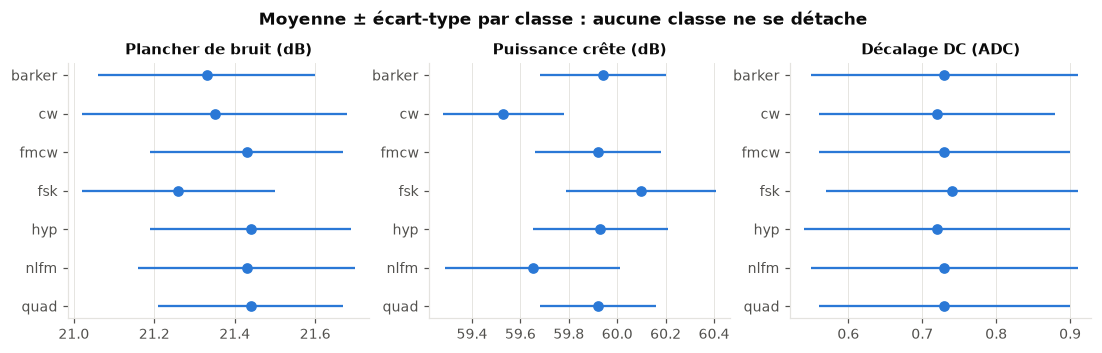

In [13]:
rows = []
for r in train[::20]:
    iq = pulse_iq(r)
    p = np.abs(iq) ** 2
    rows.append(dict(label=r.label,
                     noise_floor_db=10 * np.log10(p[NOISE_WIN].mean()),
                     peak_power_db=10 * np.log10(np.percentile(p, 99)),
                     dc_offset=np.abs(iq[NOISE_WIN].mean())))
shortcut = pd.DataFrame(rows)
stats = shortcut.groupby("label").agg(["mean", "std"]).round(2)
display(stats)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (col, title) in zip(axes, [("noise_floor_db", "Plancher de bruit (dB)"),
                                   ("peak_power_db", "Puissance crête (dB)"),
                                   ("dc_offset", "Décalage DC (ADC)")]):
    m, sd = stats[(col, "mean")], stats[(col, "std")]
    ax.errorbar(m.values, range(len(m)), xerr=sd.values, fmt="o", color=BLUE, ms=6, capsize=0, lw=1.5)
    ax.set_yticks(range(len(m)), m.index); ax.invert_yaxis()
    ax.set_title(title); ax.grid(axis="y", visible=False)
fig.suptitle("Moyenne ± écart-type par classe : aucune classe ne se détache", y=1.04, fontweight="bold")
save(fig, "09_shortcuts"); plt.show()

**Résultat :** ✅ **aucun raccourci détecté.** Plancher de bruit 21,3–21,4 dB et décalage DC ~0,7 unité ADC pour toutes
les classes. La puissance crête varie un peu (`cw` 59,5 dB, `fsk` 60,1 dB) : l'écart (≤ 0,6 dB) reste du même ordre
que la variabilité à l'intérieur d'une classe, et il disparaît dès qu'on normalise chaque pulse.

**Conséquence :** bonne nouvelle, le modèle devra apprendre la forme de la modulation. On garde quand même
une **normalisation par pulse** (règle fixe autorisée) pour que l'amplitude absolue ne serve jamais d'indice,
y compris après ajout de bruit.

## 10. Écrêtage int16 à très bas SNR

**Ce qu'on vérifie :** les taux officiels de valeurs écrêtées (0,000068 % à −20 dB, 0,239 % à −25 dB, 5,38 % à −30 dB).
**Comment :** on bruite un pulse sur trois configurations avec le bruitage officiel et on compte les valeurs à ±32767/−32768.

,SNR demandé,mesuré (%),officiel (%)
0,-20,0.000,0.000068
1,-25,0.242,0.239000
2,-30,5.429,5.380000


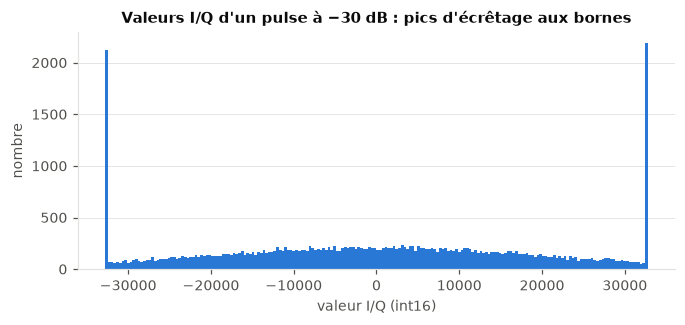

In [14]:
sample = list(first_pulse.values())[::3]
official = {-20: 0.000068, -25: 0.239, -30: 5.38}
rows = []
for snr in official:
    clipped = [np.mean((v == 32767) | (v == -32768)) for v in
               (degrade_official(load_row(r), r.source_file, snr, r.pulse_index) for r in sample)]
    rows.append({"SNR demandé": snr, "mesuré (%)": round(100 * np.mean(clipped), 3), "officiel (%)": official[snr]})
display(pd.DataFrame(rows))

ref = examples["cw"]
row = degrade_official(load_row(ref), ref.source_file, -30, ref.pulse_index).astype(float)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(row, bins=200, color=BLUE)
ax.set(xlabel="valeur I/Q (int16)", ylabel="nombre", title="Valeurs I/Q d'un pulse à −30 dB : pics d'écrêtage aux bornes")
ax.grid(axis="x", visible=False)
save(fig, "10_clipping"); plt.show()

**Résultat :** ✅ **confirmé** : 0 % / 0,24 % / 5,43 % mesurés, cohérents avec les chiffres officiels.
On voit les deux pics aux bornes ±32 768 sur l'histogramme.

**Conséquence :** à −30 dB le bruit n'est plus parfaitement gaussien. Comme on génère le bruit avec la fonction
officielle, l'entraînement voit exactement le même écrêtage que le test : rien à corriger.

## 11. Synthèse : ce qui est validé et ce que ça change

| # | Affirmation | Verdict | Décision pour le pipeline |
| --- | --- | --- | --- |
| 1 | Classes déséquilibrées (fsk ×16 cw) | ✅ | Loss pondérée ou batchs équilibrés ; suivre le rappel de `cw` |
| 2 | Pulse centré dans l'enregistrement | ✅ exact à 70,3 µs | Recadrage fixe 19–122 µs autorisé (−27 % de données inutiles) |
| 3 | SNR dans un pulse court < SNR demandé | ❌ c'est l'inverse (+9,9 dB à 10 µs) | Analyser les scores par durée en plus de par SNR |
| 4 | ~1/3 sans bruit à +30 dB | ✅ 33,3 % (tous les 10 µs) | Ne pas sur-représenter les SNR hauts à l'entraînement |
| 5 | Classes reconnaissables sur spectrogramme | ✅ à fort SNR ; ⚠️ `barker`↔`cw` et chirps entre eux à bas SNR | Surveiller ces paires dans les matrices de confusion ; garder les détails fins |
| 6 | Grande variabilité intra-classe | ✅ très forte + artefact miroir du récepteur | Pooling global ; tester miroir fréquentiel et décalage de fréquence |
| 7 | Compromis fenêtre STFT | ✅ | Départ n_fft = 256 ; tester l'empilement multi-résolution 64 + 256 |
| 8 | Raccourcis d'acquisition | ✅ aucun | Normalisation par pulse par sécurité |
| 9 | Écrêtage à −30 dB | ✅ 5,43 % | Rien à faire : bruit officiel utilisé partout |
| 10 | Spectre bilatéral nécessaire | ✅ fréquences négatives présentes | STFT bilatérale (`onesided=False`) |